# 03 · Organoid development (5–8 months)
Dryad dataset (Sharf et al. 2022, Nat. Commun.): organoid L1 (array 2953), MaxOne, recorded at 5, 6, 7 and 8 months. Raw recordings stored outside the repo.

In [ ]:
import os # environment settings
from pathlib import Path # file paths
os.environ["HDF5_PLUGIN_PATH"] = str(Path.home() / "hdf5_plugin_path_maxwell") # MaxWell decompression plugin; before importing spikeinterface

import numpy as np # arrays and maths
import spikeinterface.extractors as se # file readers

data_dir = Path("/Volumes/ADATA HD710/github/hdmea-organoid-pipeline") # folder with the 4 recordings
ages = [5, 6, 7, 8] # organoid age in months; drop one to skip that file
files = {age: data_dir / f"Development_2953_{age}month.raw.h5" for age in ages} # age -> file path

for age, f in files.items(): # one block per recording
    print(f"--- {age} months: {f.name} ---") # header
    print("Exists:", f.exists()) # should be True
    rec = se.read_maxwell(f) # open (metadata only, fast)
    print(f"Channels: {rec.get_num_channels()}") # electrodes recorded
    print(f"Sampling rate: {rec.get_sampling_frequency():.0f} Hz") # expect 20000
    print(f"Duration: {rec.get_total_duration():.1f} s") # recording length
    print(f"Gain: {rec.get_channel_gains()[0]:.3f} µV per ADC count\n") # compare with the test file (6.294)

--- 5 months: Development_2953_5month.raw.h5 ---
Exists: True
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
Channels: 1020
Sampling rate: 20000 Hz
Duration: 179.8 s
Gain: 6.294 µV per ADC count

--- 6 months: Development_2953_6month.raw.h5 ---
Exists: True
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
Channels: 1020
Sampling rate: 20000 Hz
Duration: 180.2 s
Gain: 6.294 µV per ADC count

--- 7 months: Development_2953_7month.raw.h5 ---
Exists: True
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
Channels: 1020
Sampling rate: 20000 Hz
Duration: 179.8 s
Gain: 6.294 µV per ADC count

--- 8 months: Development_2953_8month.raw.h5 ---
Exists: True
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwe

## 1. Sort one recording

In [ ]:
import spikeinterface as si # core SpikeInterface
import spikeinterface.preprocessing as spre # cleaning tools
import spikeinterface.sorters as ss # spike sorters

age_sort = 5 # which recording to sort: 5, 6, 7 or 8
sort_root = data_dir / "sorting" # where sorting results are saved
sort_dir = sort_root / f"sc2_{age_sort}month" # one folder per age
si.set_global_job_kwargs(n_jobs=4, progress_bar=True) # 4 cores + progress bars

rec = se.read_maxwell(files[age_sort]) # open the chosen recording
rec_s = spre.unsigned_to_signed(rec) # uint16 -> signed, ready for the sorter
rec_s = rec_s.select_channels(rec_s.get_channel_ids()) # keep only the 1020 declared channels -> drops the 8 extra columns
print(rec_s) # check: 1020 channels, ~180 s

x = rec_s.get_traces(start_frame=0, end_frame=10) # read just 10 samples
print("Data shape:", x.shape, "| channels declared:", rec_s.get_num_channels()) # columns should equal 1020

run_sorting = False # True = sort now (long!); set to False afterwards to just load the saved result
if run_sorting: # only when you ask for it
    sorting = ss.run_sorter(
        "spykingcircus2", # which sorter
        rec_s, # signed, unfiltered: SC2 filters itself
        folder=sort_dir, # where sorting results are saved
        remove_existing_folder=True, # overwrite old results
        verbose=True, # print progress
        deterministic_peaks_detection=True, # no early stopping
        apply_motion_correction=False, # organoid slice on the chip barely moves
    )
else:
    sorting = ss.read_sorter_folder(sort_dir) # load the saved result
print(f"Units found: {len(sorting.get_unit_ids())}") # number of neurons

The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
ChannelSliceRecording: 1020 channels - 20.0kHz - 1 segments - 3,596,600 samples 
                       179.83s (3.00 minutes) - int16 dtype - 6.83 GiB
Data shape: (10, 1020) | channels declared: 1020
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
Units found: 134


## 2. Sort the remaining ages

In [ ]:
import time # to measure run time

run_loop = False # True = sort the ages below (long!); False = skip, results are already saved
ages_todo = [6, 7, 8] # recordings to sort when run_loop is True
for age in (ages_todo if run_loop else []): # loops over nothing when run_loop is False
    t0 = time.time() # start the clock
    rec_a = se.read_maxwell(files[age]) # open this age's recording
    rec_a = spre.unsigned_to_signed(rec_a) # uint16 -> signed
    rec_a = rec_a.select_channels(rec_a.get_channel_ids()) # keep only the 1020 real channels (drops the 8 extra rows)
    print(f"\n=== {age} months: {rec_a.get_num_channels()} channels, {rec_a.get_total_duration():.1f} s ===") # check before sorting
    sorting_a = ss.run_sorter(
        "spykingcircus2", # which sorter
        rec_a, # signed, unfiltered
        folder=sort_root / f"sc2_{age}month", # same folder naming as the 5-month one
        remove_existing_folder=True, # overwrite old results
        verbose=False, # less output, since we run 3 in a row
        deterministic_peaks_detection=True, # no early stopping
        apply_motion_correction=False, # slice barely moves
    )
    print(f"{age} months: {len(sorting_a.get_unit_ids())} units, {(time.time() - t0) / 60:.1f} min") # result + run time

## 3. Quality check per age
Same criteria as notebook 02: remove duplicates (≤ 0.3 ms), then label each unit single (SNR ≥ 5 and < 1% ISIs under 1.5 ms) or MUA.
Tables are saved as CSV so they don't need recomputing.

In [9]:
import pandas as pd # tables
from spikeinterface.curation import remove_duplicated_spikes # removes double-counted spikes

dup_ms = 0.3 # duplicate window in ms
isi_limit_ms = 1.5 # refractory period in ms
snr_min = 5 # minimum SNR for a single unit
viol_max = 1.0 # maximum % refractory violations for a single unit
qc_dir = data_dir / "qc" # where the QC tables are saved
qc_dir.mkdir(exist_ok=True) # create the folder if missing

run_qc = False # True = compute (slow); False = load the saved tables
unit_tables = {} # age -> table with one row per unit
for age in ages: # 5, 6, 7, 8
    csv = qc_dir / f"qc_{age}month.csv" # saved table for this age
    if run_qc: # compute
        rec_a = se.read_maxwell(files[age]) # open recording
        rec_a = spre.unsigned_to_signed(rec_a) # uint16 -> signed
        rec_a = rec_a.select_channels(rec_a.get_channel_ids()) # keep the 1020 real channels
        rec_fa = spre.bandpass_filter(rec_a, freq_min=300, freq_max=6000, dtype="float32") # filtered, for spike shapes
        fs = rec_a.get_sampling_frequency() # 20000 Hz
        dur_a = rec_a.get_total_duration() # length in s

        sort_a = ss.read_sorter_folder(sort_root / f"sc2_{age}month") # load the saved sorting
        sort_a = remove_duplicated_spikes(sort_a, censored_period_ms=dup_ms, method="keep_first") # drop duplicates

        an = si.create_sorting_analyzer(sort_a, rec_fa, sparse=True, format="memory") # link spikes to voltage
        an.compute(["random_spikes", "templates", "noise_levels"]) # average spike shape per unit + noise (no full waveforms: saves RAM)
        snr = an.compute("quality_metrics", metric_names=["snr"]).get_data()["snr"] # SNR per unit

        rows = [] # one dict per unit
        for u in sort_a.get_unit_ids(): # every unit
            st = sort_a.get_unit_spike_train(u) # spike times in samples
            isi_ms = np.diff(st) / fs * 1000 # ISIs in ms
            pct = 100 * (isi_ms < isi_limit_ms).sum() / max(len(isi_ms), 1) # % refractory violations
            label = "single" if (snr[u] >= snr_min and pct <= viol_max) else "MUA" # quality label
            rows.append({"unit": u, "spikes": len(st), "rate_hz": len(st) / dur_a, "snr": snr[u], "viol_pct": pct, "label": label}) # store
        df = pd.DataFrame(rows).set_index("unit") # table for this age
        df.to_csv(csv) # save, so next time we just load
    else:
        df = pd.read_csv(csv, index_col="unit") # load the saved table
    unit_tables[age] = df # keep it
    print(f"{age} months: {len(df)} units -> {(df.label == 'single').sum()} single, {(df.label == 'MUA').sum()} MUA") # progress line

summary = pd.DataFrame({ # one row per age
    "units": {a: len(d) for a, d in unit_tables.items()}, # all units
    "single": {a: (d.label == "single").sum() for a, d in unit_tables.items()}, # single units
    "MUA": {a: (d.label == "MUA").sum() for a, d in unit_tables.items()}, # multi-unit
    "median_rate_single_hz": {a: d[d.label == "single"].rate_hz.median() for a, d in unit_tables.items()}, # typical single-unit rate
    "total_spikes": {a: d.spikes.sum() for a, d in unit_tables.items()}, # all spikes after duplicate removal
})
summary.index.name = "age_months" # label the rows
print("\n", summary.round(2)) # final table

5 months: 134 units -> 3 single, 131 MUA
6 months: 492 units -> 69 single, 423 MUA
7 months: 690 units -> 24 single, 666 MUA
8 months: 573 units -> 60 single, 513 MUA

             units  single  MUA  median_rate_single_hz  total_spikes
age_months                                                         
5             134       3  131                   1.01        325540
6             492      69  423                   0.63        398774
7             690      24  666                   1.03        424375
8             573      60  513                   0.97        488598


## 4. Development across 5–8 months
Few units pass the single-unit criteria (small organoid spikes, median SNR ~2–3), so network-level measures use all units (single + MUA).
Population rate = all spikes summed in 50 ms bins. Network burst = population rate crossing mean + 3 SD.

In [22]:
import sys # to let the notebook find src/
import matplotlib.pyplot as plt # plotting
sys.path.append(str(Path("..").resolve())) # add the repo root to Python's search path
from src.spike_metrics import cv_isi, population_rate, count_bursts # our reusable functions

figs_dir = Path("../figures") # repo figures folder (committed)
figs_dir.mkdir(exist_ok=True) # create if missing
bin_ms = 50 # population-rate bin in ms
k_burst = 3 # burst threshold = mean + k × SD
min_spikes_cv = 20 # minimum spikes for a reliable CV

res = {} # age -> results
for age in ages: # 5, 6, 7, 8
    sort_a = ss.read_sorter_folder(sort_root / f"sc2_{age}month") # saved sorting
    sort_a = remove_duplicated_spikes(sort_a, censored_period_ms=dup_ms, method="keep_first") # same cleaning as QC
    fs = sort_a.get_sampling_frequency() # 20000 Hz
    dur_a = se.read_maxwell(files[age]).get_total_duration() # length in s
    trains = [sort_a.get_unit_spike_train(u) / fs for u in sort_a.get_unit_ids()] # spike times in s per unit

    rates = np.array([len(t) / dur_a for t in trains]) # firing rate per unit (Hz)
    cvs = np.array([cv_isi(t) for t in trains if len(t) >= min_spikes_cv]) # CV per unit, via src
    pop_rate, edges = population_rate(trains, dur_a, bin_ms / 1000) # population rate, via src
    n_bursts, thr = count_bursts(pop_rate, k_burst) # network bursts, via src

    res[age] = dict(trains=trains, dur=dur_a, rates=rates, cvs=cvs, pop_rate=pop_rate, edges=edges, thr=thr,
                    bursts_per_min=n_bursts / dur_a * 60) # store; trains + dur are reused for STTC
    print(f"{age} m: {len(trains)} units | median rate {np.median(rates):.2f} Hz | median CV {np.median(cvs):.2f} | "
          f"pop. rate {pop_rate.mean():.0f} spikes/s | {n_bursts} bursts ({res[age]['bursts_per_min']:.1f}/min)") # summary

The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
5 m: 134 units | median rate 12.13 Hz | median CV 1.40 | pop. rate 1810 spikes/s | 6 bursts (2.0/min)
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
6 m: 492 units | median rate 2.85 Hz | median CV 1.35 | pop. rate 2213 spikes/s | 23 bursts (7.7/min)
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
7 m: 690 units | media

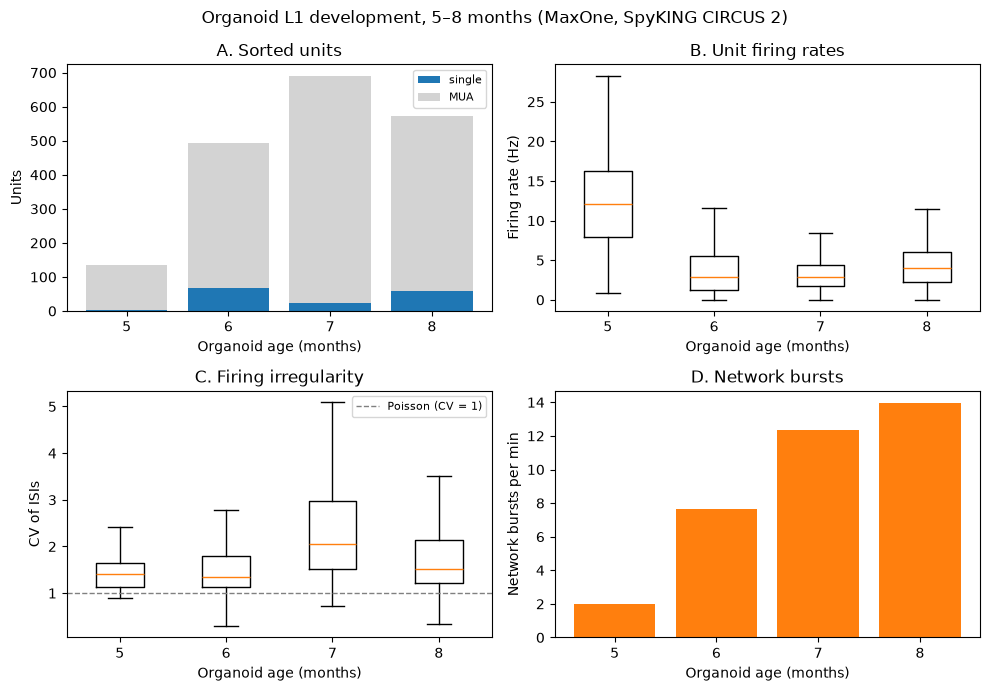

In [20]:
# Figure 1: summary across ages
fig, ax = plt.subplots(2, 2, figsize=(10, 7)) # 4 panels
single = [summary.loc[a, "single"] for a in ages] # single units per age
mua = [summary.loc[a, "MUA"] for a in ages] # MUA per age
ax[0, 0].bar(ages, single, color="tab:blue", label="single") # bottom part of bars
ax[0, 0].bar(ages, mua, bottom=single, color="lightgrey", label="MUA") # stacked on top
ax[0, 0].set_xlabel("Organoid age (months)"); ax[0, 0].set_ylabel("Units"); ax[0, 0].set_title("A. Sorted units")
ax[0, 0].legend(fontsize=8) # labels

ax[0, 1].boxplot([res[a]["rates"] for a in ages], tick_labels=ages, showfliers=False) # rate distribution per age
ax[0, 1].set_xlabel("Organoid age (months)"); ax[0, 1].set_ylabel("Firing rate (Hz)"); ax[0, 1].set_title("B. Unit firing rates") # labels

ax[1, 0].boxplot([res[a]["cvs"] for a in ages], tick_labels=ages, showfliers=False) # CV distribution per age
ax[1, 0].axhline(1, color="grey", ls="--", lw=1, label="Poisson (CV = 1)") # random-firing reference
ax[1, 0].set_xlabel("Organoid age (months)"); ax[1, 0].set_ylabel("CV of ISIs"); ax[1, 0].set_title("C. Firing irregularity")
ax[1, 0].legend(fontsize=8) # labels

ax[1, 1].bar(ages, [res[a]["bursts_per_min"] for a in ages], color="tab:orange") # burst rate per age
ax[1, 1].set_xlabel("Organoid age (months)"); ax[1, 1].set_ylabel("Network bursts per min"); ax[1, 1].set_title("D. Network bursts") # labels
ax[0, 0].set_xticks(ages) # x ticks only at the 4 ages
ax[1, 1].set_xticks(ages) # same for the burst panel
fig.suptitle("Organoid L1 development, 5–8 months (MaxOne, SpyKING CIRCUS 2)", fontsize=12) # overall figure title
plt.tight_layout() # avoid overlaps
fig.savefig(figs_dir / "development_summary.png", dpi=200) # save for GitHub
plt.show() # draw

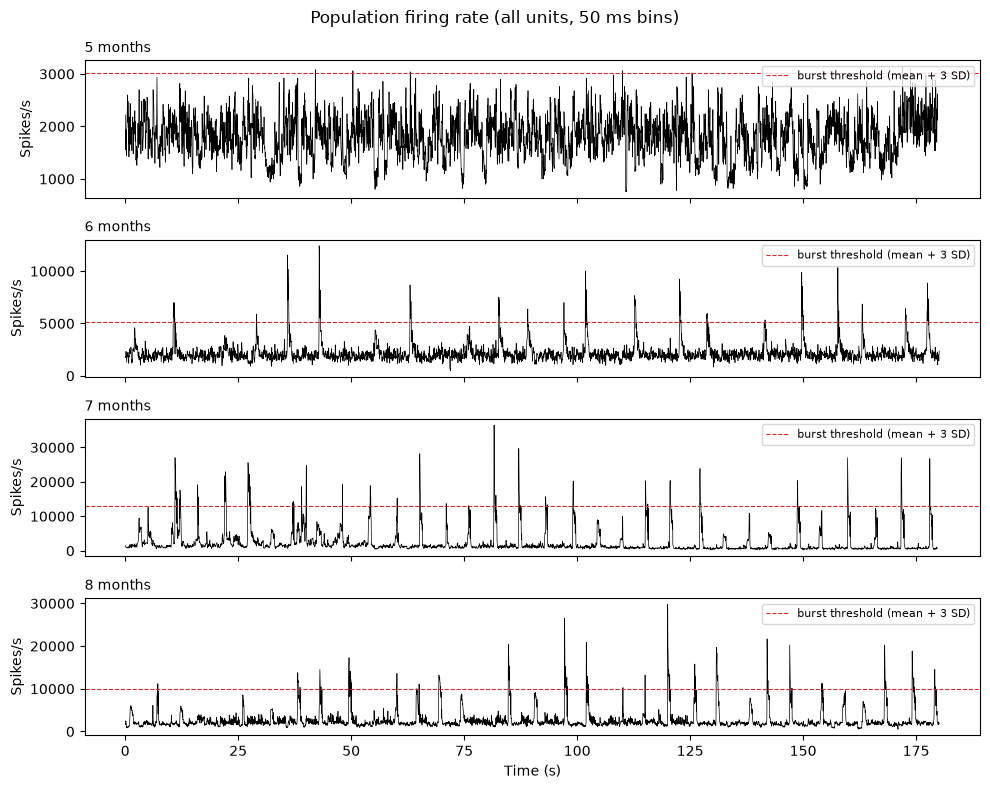

In [21]:
# Figure 2: population rate over time, one row per age
fig, ax = plt.subplots(len(ages), 1, figsize=(10, 2 * len(ages)), sharex=True) # stacked traces
for i, a in enumerate(ages): # one row per age
    t_mid = (res[a]["edges"][:-1] + res[a]["edges"][1:]) / 2 # bin centres in s
    ax[i].plot(t_mid, res[a]["pop_rate"], lw=0.5, color="black") # population rate
    ax[i].axhline(res[a]["thr"], color="tab:red", lw=0.8, ls="--", label=f"burst threshold (mean + {k_burst} SD)") # threshold line with a label
    ax[i].legend(fontsize=8, loc="upper right") # small legend in each panel
    ax[i].set_ylabel("Spikes/s"); ax[i].set_title(f"{a} months", loc="left", fontsize=10) # labels
ax[-1].set_xlabel("Time (s)") # x label once, at the bottom
fig.suptitle(f"Population firing rate (all units, {bin_ms} ms bins)", fontsize=12) # overall title; updates if you change bin_ms
plt.tight_layout() # avoid overlaps
fig.savefig(figs_dir / "population_rate.png", dpi=200) # save for GitHub
plt.show() # draw

## 5. Pairwise synchrony (STTC)
STTC between the 50 most active units per age (±10 ms). Range −1 to 1; 0 = chance level.
Caveat: one neuron split into two units would give a very high STTC.

In [27]:
import importlib # to reload src after editing it
import src.spike_metrics as sm # our functions module
importlib.reload(sm) # load the new STTC functions without restarting the kernel
from src.spike_metrics import sttc # STTC function

A = np.array([0.12, 0.35, 0.38, 0.51, 0.64, 0.83, 0.86, 0.89]) # toy neuron A from your theory session (s)
B = np.array([0.125, 0.355, 0.645, 0.835, 0.885, 0.95]) # toy neuron B (s)
print(f"Toy check: STTC = {sttc(A, B, 0.010, 1.0):.2f} (by hand: 0.66)") # must match your hand calculation

dt_sttc = 0.050 # coincidence window in s (±); 0.050 = ±50 ms, the burst timescale
n_top = None # None = all units; a number = only that many most active units
sttc_vals = {} # age -> STTC values
for age in ages: # 5, 6, 7, 8
    trains, dur_a = res[age]["trains"], res[age]["dur"] # from the analysis cell
    top = np.argsort([len(t) for t in trains])[::-1][:n_top] # all units if n_top is None (Python treats [:None] as "everything")
    vals = [sttc(trains[i], trains[j], dt_sttc, dur_a) for k, i in enumerate(top) for j in top[k + 1:]] # every pair once
    sttc_vals[age] = np.array(vals) # store
    print(f"{age} m: {len(vals)} pairs | median STTC {np.median(vals):.2f}") # summary

Toy check: STTC = 0.66 (by hand: 0.66)
5 m: 8911 pairs | median STTC 0.01
6 m: 120786 pairs | median STTC 0.03
7 m: 237705 pairs | median STTC 0.16
8 m: 163878 pairs | median STTC 0.08


In [ ]:
fig, ax = plt.subplots(figsize=(5, 4)) # one panel
ax.boxplot([sttc_vals[a] for a in ages], tick_labels=ages, showfliers=False) # STTC distribution per age
ax.axhline(0, color="grey", ls="--", lw=1, label="chance level") # no correlation
ax.set_xlabel("Organoid age (months)") # x label
ax.set_ylabel(f"STTC (±{dt_sttc * 1000:.0f} ms)") # y label follows dt_sttc
ax.legend(fontsize=8) # small legend
fig.suptitle(f"Pairwise synchrony, {'all' if n_top is None else n_top} {'units' if n_top is None else 'most active units'}", fontsize=12) # title follows n_top
plt.tight_layout() # avoid overlaps
fig.savefig(figs_dir / "sttc.png", dpi=200) # save for GitHub
plt.show() # draw